## Task 1: Data Cleaning, Preprocessing, and Training Baseline Model without 'sex'



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Load the dataset
df = pd.read_csv('/content/adult.csv')
print("Initial dataset shape:", df.shape)

# Clean columns and strip spaces from string fields (often needed with UCI data)
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].str.strip()

# 2. Remove rows with '?' values
df = df.replace('?', np.nan).dropna()
print("Shape after removing rows with '?':", df.shape)

# 3. Identify target and sensitive attributes
# Checking the column name for income target
income_col = 'income' if 'income' in df.columns else 'class'
if income_col not in df.columns:
    # search for any column that looks like income
    income_col = [c for c in df.columns if 'income' in c.lower() or 'class' in c.lower()][0]

print(f"Target column identified: {income_col}")

# Standardize target labels to binary 0 and 1
# >50K or >50K. as 1, <=50K or <=50K. as 0
df['target'] = df[income_col].apply(lambda x: 1 if '>50K' in str(x) else 0)

# Save the sensitive attribute 'sex'
sensitive_col = 'sex' if 'sex' in df.columns else 'gender'

# 4. Separate X and Y. We must drop both the target column, original income column, and 'sex' from X.
X_raw = df.drop(columns=['target', income_col, sensitive_col])
y = df['target']
sensitive_attr = df[sensitive_col]

# 5. Preprocess and encode categorical columns in X
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# Standardize features for logistic regression stability
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_encoded.columns)

# 6. Stratified 70:30 train-test split
# We must split X, y, and our sensitive attribute systematically so indices match
X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X_scaled_df,
    y,
    sensitive_attr,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 7. Train Baseline Logistic Regression model
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Baseline model trained successfully!")
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Initial dataset shape: (32561, 15)
Shape after removing rows with '?': (30162, 15)
Target column identified: income
Baseline model trained successfully!
Train size: 21113, Test size: 9049


## Task 2 & Task 3: Fairness Auditing of the Baseline Model


In [3]:
!pip install -q fairlearn

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference
)
from sklearn.metrics import accuracy_score, recall_score

# Helper function to compute FPR
def false_positive_rate(y_true, y_pred):
    # FPR = FP / (FP + TN)
    # Which is equivalent to recall of the negative class when 0 is labeled as positive
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return fp / (fp + tn) if (fp + tn) > 0 else 0.0

# Define the metric dictionary
metrics_dict = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': recall_score,
    'fpr': false_positive_rate
}

# Instantiate MetricFrame
metric_frame = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=A_test
)

print("=== Task 2: MetricFrame Overall Results ===")
print(metric_frame.overall)
print("\n=== Task 2: MetricFrame by Sensitive Attribute (Sex) ===")
print(metric_frame.by_group)

# Task 3: Demographic Parity & Equalized Odds
dp_diff = demographic_parity_difference(y_test, y_pred_baseline, sensitive_features=A_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred_baseline, sensitive_features=A_test)
eo_diff = equalized_odds_difference(y_test, y_pred_baseline, sensitive_features=A_test)

print("\n=== Task 3: Fairness Differences and Ratios ===")
print(f"Demographic Parity Difference: {dp_diff:.4f}")
print(f"Demographic Parity Ratio: {dp_ratio:.4f}")
print(f"Equalized Odds Difference: {eo_diff:.4f}")

=== Task 2: MetricFrame Overall Results ===
accuracy          0.848492
selection_rate    0.203227
tpr               0.603908
fpr               0.070472
dtype: float64

=== Task 2: MetricFrame by Sensitive Attribute (Sex) ===
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.920509        0.088438  0.540123  0.031758
Male    0.814423        0.257529  0.614627  0.094187

=== Task 3: Fairness Differences and Ratios ===
Demographic Parity Difference: 0.1691
Demographic Parity Ratio: 0.3434
Equalized Odds Difference: 0.0745


## Task 4 & Task 5: Bias Mitigation using Fairlearn ThresholdOptimizer



In [4]:
from fairlearn.postprocessing import ThresholdOptimizer

# --- Task 4: ThresholdOptimizer with Demographic Parity ---
to_dp = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="demographic_parity",
    predict_method="predict_proba"
)

# Fit ThresholdOptimizer
to_dp.fit(X_train, y_train, sensitive_features=A_train)

# Predict using mitigated model
y_pred_to_dp = to_dp.predict(X_test, sensitive_features=A_test)

# Compute MetricFrame for demographic parity model
metric_frame_dp = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_to_dp,
    sensitive_features=A_test
)

# --- Task 5: ThresholdOptimizer with Equalized Odds ---
to_eo = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="equalized_odds",
    predict_method="predict_proba"
)

to_eo.fit(X_train, y_train, sensitive_features=A_train)
y_pred_to_eo = to_eo.predict(X_test, sensitive_features=A_test)

metric_frame_eo = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_to_eo,
    sensitive_features=A_test
)

print("=== Task 4 Metrics (Demographic Parity Mitigation) ===")
print(metric_frame_dp.by_group)
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test, y_pred_to_dp, sensitive_features=A_test):.4f}")
print(f"Equalized Odds Difference: {equalized_odds_difference(y_test, y_pred_to_dp, sensitive_features=A_test):.4f}")

print("\n=== Task 5 Metrics (Equalized Odds Mitigation) ===")
print(metric_frame_eo.by_group)
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test, y_pred_to_eo, sensitive_features=A_test):.4f}")
print(f"Equalized Odds Difference: {equalized_odds_difference(y_test, y_pred_to_eo, sensitive_features=A_test):.4f}")

=== Task 4 Metrics (Demographic Parity Mitigation) ===
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.884377        0.176187  0.771605  0.101472
Male    0.804330        0.178414  0.472510  0.043891
Demographic Parity Difference: 0.0022
Equalized Odds Difference: 0.2991

=== Task 5 Metrics (Equalized Odds Mitigation) ===
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.872333        0.134549  0.530864  0.084818
Male    0.814586        0.228716  0.568983  0.073072
Demographic Parity Difference: 0.0942
Equalized Odds Difference: 0.0381


## Task 6: Selection-Rate Plot and Accuracy vs Fairness Comparison Table




=== Task 6: Comparison Table ===
               MODEL  ACC SEL_M SEL_F DP_DIFF EO_DIFF
            Baseline 0.85  0.26  0.09    0.17    0.07
TO: demographic_par. 0.83  0.18  0.18    0.00    0.30
  TO: equalized_odds 0.83  0.23  0.13    0.09    0.04

Plot saved as 'selection_rate_by_sex.png'


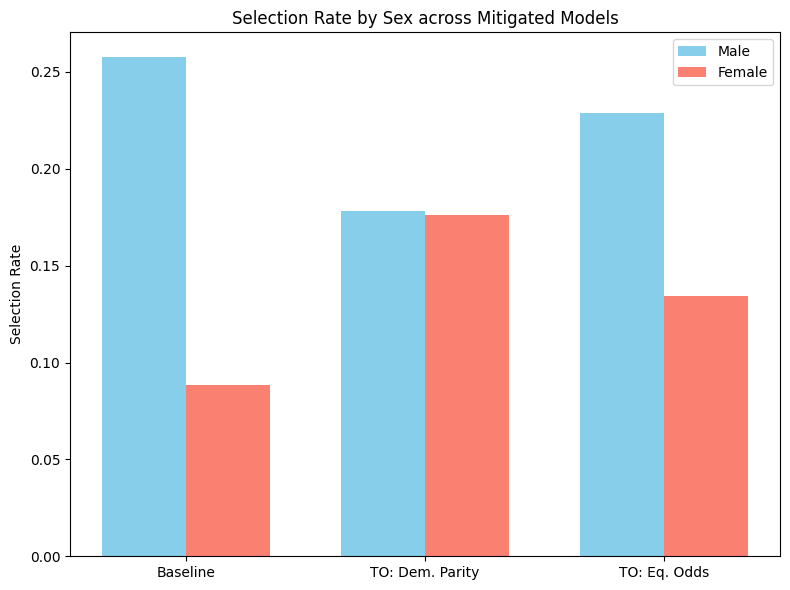

In [5]:
import matplotlib.pyplot as plt

# 1. Build the comparison table
# Calculate overall accuracy for each model
acc_base = metric_frame.overall['accuracy']
acc_dp = metric_frame_dp.overall['accuracy']
acc_eo = metric_frame_eo.overall['accuracy']

# Selection rates
sel_m_base = metric_frame.by_group['selection_rate']['Male']
sel_f_base = metric_frame.by_group['selection_rate']['Female']

sel_m_dp = metric_frame_dp.by_group['selection_rate']['Male']
sel_f_dp = metric_frame_dp.by_group['selection_rate']['Female']

sel_m_eo = metric_frame_eo.by_group['selection_rate']['Male']
sel_f_eo = metric_frame_eo.by_group['selection_rate']['Female']

# Differences
dp_diff_base = dp_diff
dp_diff_dp = demographic_parity_difference(y_test, y_pred_to_dp, sensitive_features=A_test)
dp_diff_eo = demographic_parity_difference(y_test, y_pred_to_eo, sensitive_features=A_test)

eo_diff_base = eo_diff
eo_diff_dp = equalized_odds_difference(y_test, y_pred_to_dp, sensitive_features=A_test)
eo_diff_eo = equalized_odds_difference(y_test, y_pred_to_eo, sensitive_features=A_test)

comparison_data = {
    'MODEL': ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds'],
    'ACC': [acc_base, acc_dp, acc_eo],
    'SEL_M': [sel_m_base, sel_m_dp, sel_m_eo],
    'SEL_F': [sel_f_base, sel_f_dp, sel_f_eo],
    'DP_DIFF': [dp_diff_base, dp_diff_dp, dp_diff_eo],
    'EO_DIFF': [eo_diff_base, eo_diff_dp, eo_diff_eo]
}

comparison_df = pd.DataFrame(comparison_data)
print("=== Task 6: Comparison Table ===")
print(comparison_df.to_string(index=False, formatters={
    'ACC': '{:,.2f}'.format,
    'SEL_M': '{:,.2f}'.format,
    'SEL_F': '{:,.2f}'.format,
    'DP_DIFF': '{:,.2f}'.format,
    'EO_DIFF': '{:,.2f}'.format
}))

# 2. Visual Plot of Selection Rate by Sex
labels = ['Baseline', 'TO: Dem. Parity', 'TO: Eq. Odds']
male_rates = [sel_m_base, sel_m_dp, sel_m_eo]
female_rates = [sel_f_base, sel_f_dp, sel_f_eo]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x - width/2, male_rates, width, label='Male', color='skyblue')
rects2 = ax.bar(x + width/2, female_rates, width, label='Female', color='salmon')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex across Mitigated Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

fig.tight_layout()

# Save the plot as required by the examiners
plt.savefig('selection_rate_by_sex.png')
print("\nPlot saved as 'selection_rate_by_sex.png'")
plt.show()